Anggota Kelompok:

1. Orchidea Savira Putri Arief Dhidin (25031554174)

2. Dentar Muhammad Ababilla (25031554277)

# **Exercise 7 Text Clustering**
Try applying all clustering methods on the text you have feature engineering from the previous exercise and analyze the given results.

## **1. Persiapan Environment & Import Library**

In [1]:
!pip install wordcloud -q

In [2]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from wordcloud import WordCloud

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn import metrics
from sklearn.decomposition import PCA
from scipy.cluster.hierarchy import dendrogram, linkage

print("Semua library berhasil dimuat!")

Semua library berhasil dimuat!


## **2. Load Data Hasil Preprocessing**

In [3]:
df_http = pd.read_csv('hasil_preprocessing_http.csv')
df_music = pd.read_csv('hasil_preprocessing_music_api.csv')

df_http['prepro'] = df_http['quote_final'].fillna('').astype(str)
df_music['prepro'] = df_music['music_final'].fillna('').astype(str)

df_http = df_http[df_http['prepro'].str.strip() != ''].reset_index(drop=True)
df_music = df_music[df_music['prepro'].str.strip() != ''].reset_index(drop=True)

datasets = {
    'Quotes': df_http,
    'Music': df_music
}

for name, df in datasets.items():
    print(f"{name}: {len(df)} dokumen")
    print("  Contoh dokumen:", df['prepro'].iloc[0])

Quotes: 50 dokumen
  Contoh dokumen: “ world created process thinking changed without changing thinking ”
Music: 15 dokumen
  Contoh dokumen: love keyshia cole


## **3. Feature Engineering (TF-IDF)**

In [4]:
vectorizers = {}
features_tfidf = {}

for name, df in datasets.items():
    vec = TfidfVectorizer()
    X = vec.fit_transform(df['prepro'])
    vectorizers[name] = vec
    features_tfidf[name] = pd.DataFrame(X.toarray(), columns=vec.get_feature_names_out())
    print(f"{name} TF-IDF shape: {features_tfidf[name].shape}")

Quotes TF-IDF shape: (50, 319)
Music TF-IDF shape: (15, 36)


## **4. Unsupervised: KMeans Clustering**

### **A. Elbow Method (Inertia vs K)**

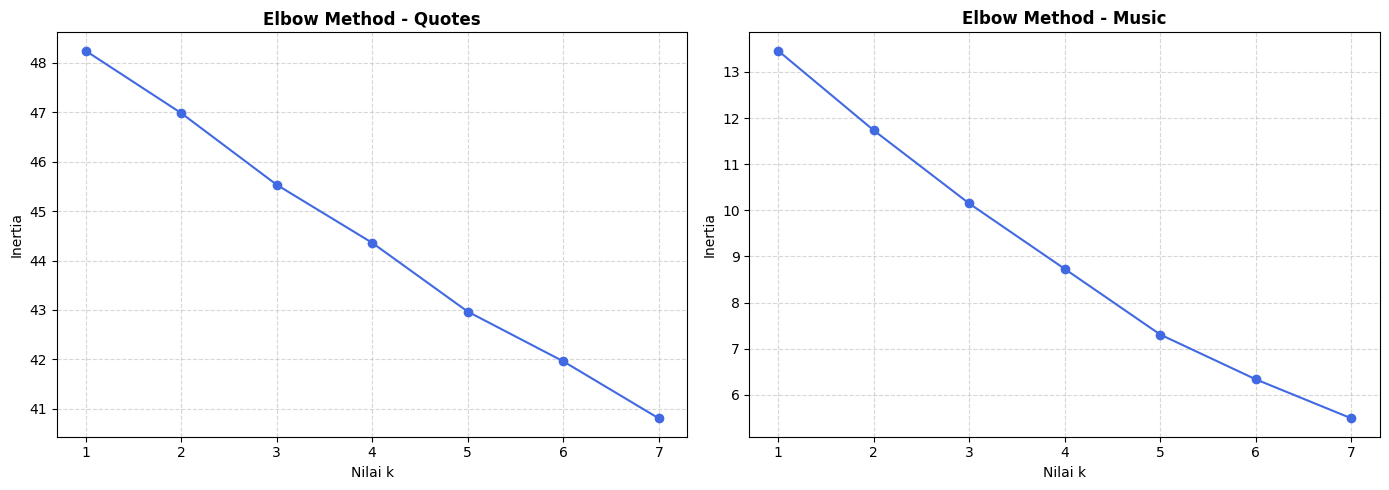

In [5]:
k_range = range(1, 8)
inertia_dict = {}

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for idx, (name, df_fe) in enumerate(features_tfidf.items()):
    inertias = []
    for k in k_range:
        km = KMeans(n_clusters=k, random_state=10, n_init=10)
        km.fit(df_fe)
        inertias.append(km.inertia_)
    inertia_dict[name] = inertias

    axes[idx].plot(list(k_range), inertias, marker='o', color='royalblue')
    axes[idx].set_title(f'Elbow Method - {name}', fontsize=12, fontweight='bold')
    axes[idx].set_xlabel('Nilai k')
    axes[idx].set_ylabel('Inertia')
    axes[idx].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

### **B. Training KMeans & Silhouette Score**

In [6]:
n_clusters_dict = {'Quotes': 3, 'Music': 3}
kmeans_models = {}

for name, df in datasets.items():
    k = n_clusters_dict[name]
    df_fe = features_tfidf[name]

    km = KMeans(n_clusters=k, random_state=10, n_init=10).fit(df_fe)
    kmeans_models[name] = km
    df['Kmeans_label'] = km.labels_

    sil_score = metrics.silhouette_score(df_fe, km.labels_, metric='euclidean')
    print(f"=== KMeans ({name}) === n_clusters = {k} | Silhouette Score: {sil_score:.4f}")
    print(df['Kmeans_label'].value_counts().sort_index().to_dict())
    display(df[['prepro', 'Kmeans_label']].head())

=== KMeans (Quotes) === n_clusters = 3 | Silhouette Score: 0.0062
{0: 33, 1: 13, 2: 4}


,prepro,Kmeans_label
0,“ world created process thinking changed witho...,0
1,“ choice harry show truly far ability ”,0
2,“ two way live life one though nothing miracle...,0
3,“ person gentleman lady pleasure good novel mu...,0
4,“ imperfection beauty madness genius better ab...,0


=== KMeans (Music) === n_clusters = 3 | Silhouette Score: 0.1009
{0: 9, 1: 3, 2: 3}


,prepro,Kmeans_label
0,love keyshia cole,0
1,love feat zacari kendrick lamar,0
2,love musiq soulchild,0
3,dream lisa,2
4,dream salvia palth,2


### **C. Visualisasi Word Cloud per Cluster KMeans**

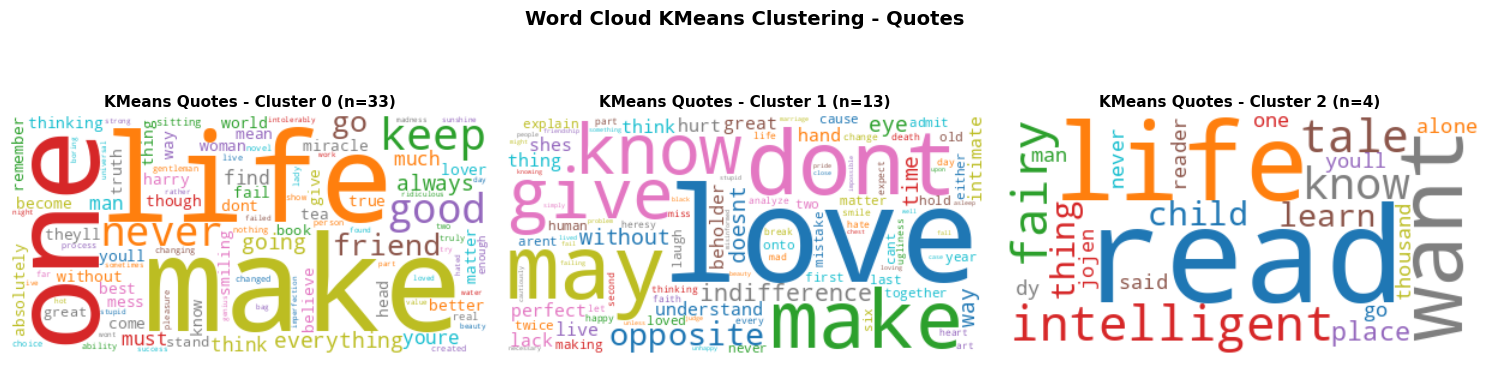

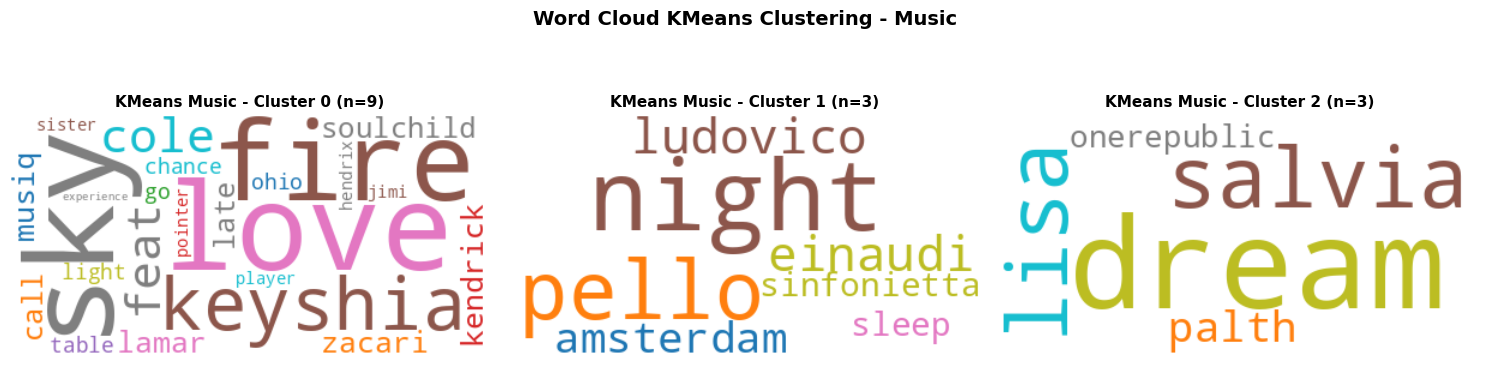

In [7]:
for name, df in datasets.items():
    k = n_clusters_dict[name]
    fig, axes = plt.subplots(1, k, figsize=(5 * k, 4))
    if k == 1:
        axes = [axes]

    for c in range(k):
        df_c = df[df['Kmeans_label'] == c]
        text_c = ' '.join(df_c['prepro'].values)
        if text_c.strip():
            wc = WordCloud(background_color='white', max_words=100, colormap='tab10').generate(text_c)
            axes[c].imshow(wc, interpolation='bilinear')
        axes[c].set_title(f'KMeans {name} - Cluster {c} (n={len(df_c)})', fontsize=11, fontweight='bold')
        axes[c].axis('off')

    plt.suptitle(f'Word Cloud KMeans Clustering - {name}', fontsize=14, fontweight='bold', y=1.02)
    plt.tight_layout()
    plt.show()

### **D. Visualisasi 2D Scatter Plot KMeans (PCA)**

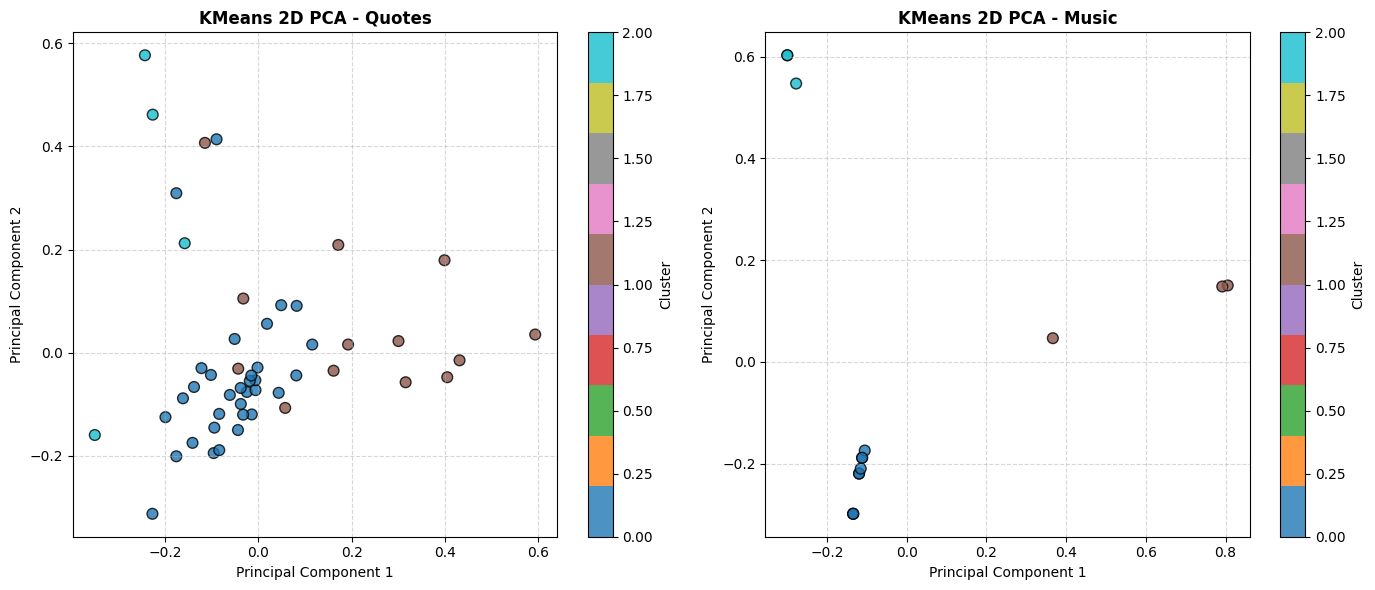

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for idx, (name, df) in enumerate(datasets.items()):
    df_fe = features_tfidf[name]
    pca = PCA(n_components=2, random_state=10)
    coords = pca.fit_transform(df_fe)

    scatter = axes[idx].scatter(coords[:, 0], coords[:, 1], c=df['Kmeans_label'], cmap='tab10', s=60, alpha=0.8, edgecolors='k')
    axes[idx].set_title(f'KMeans 2D PCA - {name}', fontsize=12, fontweight='bold')
    axes[idx].set_xlabel('Principal Component 1')
    axes[idx].set_ylabel('Principal Component 2')
    axes[idx].grid(True, linestyle='--', alpha=0.5)
    plt.colorbar(scatter, ax=axes[idx], label='Cluster')

plt.tight_layout()
plt.show()

## **5. Unsupervised: Hierarchical Clustering (Ward)**

### **A. Dendrogram**

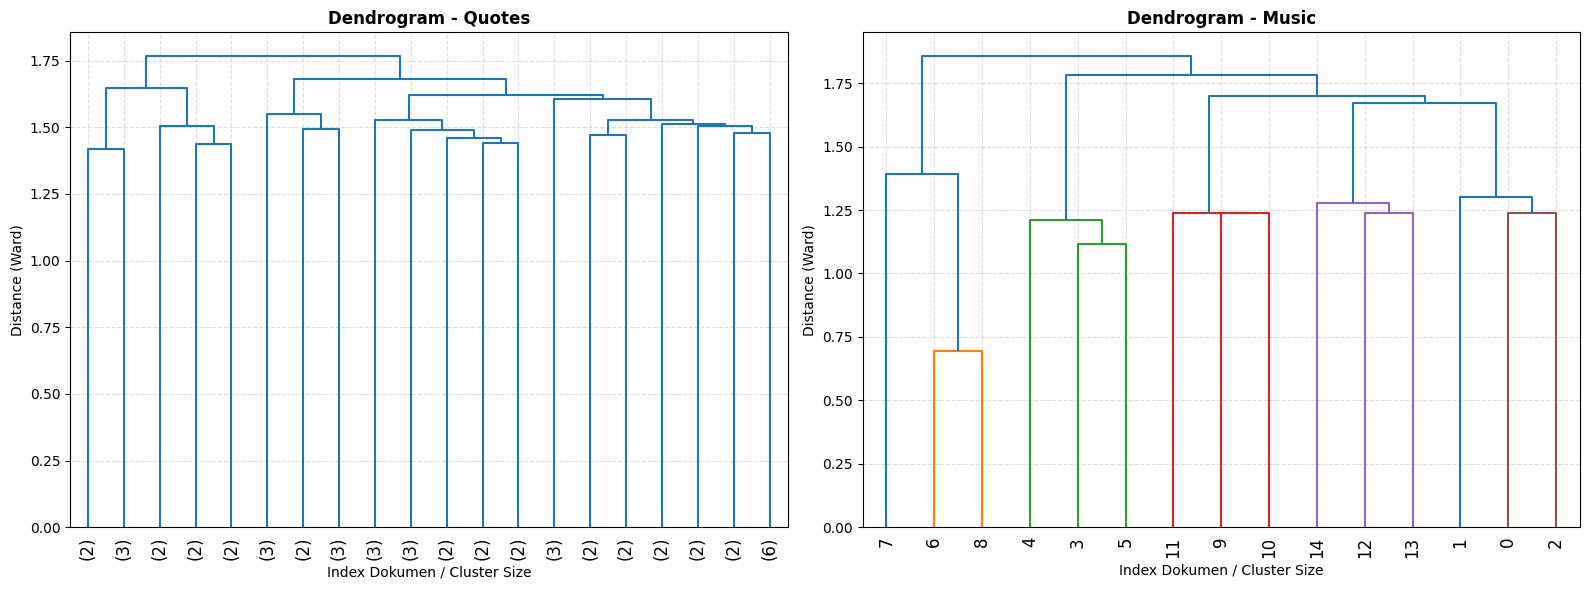

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

linkage_dict = {}
for idx, (name, df_fe) in enumerate(features_tfidf.items()):
    link = linkage(df_fe, method='ward', metric='euclidean')
    linkage_dict[name] = link
    dendrogram(link, ax=axes[idx], truncate_mode='lastp', p=20, leaf_rotation=90)
    axes[idx].set_title(f'Dendrogram - {name}', fontsize=12, fontweight='bold')
    axes[idx].set_xlabel('Index Dokumen / Cluster Size')
    axes[idx].set_ylabel('Distance (Ward)')
    axes[idx].grid(True, linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()

### **B. Training Agglomerative Clustering & Silhouette Score**

In [10]:
for name, df in datasets.items():
    k = n_clusters_dict[name]
    df_fe = features_tfidf[name]

    hierarchical = AgglomerativeClustering(n_clusters=k, linkage='ward')
    df['Ward_label'] = hierarchical.fit_predict(df_fe)

    sil_score = metrics.silhouette_score(df_fe, df['Ward_label'], metric='euclidean')
    print(f"=== Hierarchical Ward ({name}) === n_clusters = {k} | Silhouette Score: {sil_score:.4f}")
    print(df['Ward_label'].value_counts().sort_index().to_dict())
    display(df[['prepro', 'Ward_label']].head())

=== Hierarchical Ward (Quotes) === n_clusters = 3 | Silhouette Score: 0.0129
{0: 11, 1: 31, 2: 8}


,prepro,Ward_label
0,“ world created process thinking changed witho...,1
1,“ choice harry show truly far ability ”,1
2,“ two way live life one though nothing miracle...,1
3,“ person gentleman lady pleasure good novel mu...,1
4,“ imperfection beauty madness genius better ab...,1


=== Hierarchical Ward (Music) === n_clusters = 3 | Silhouette Score: 0.1009
{0: 9, 1: 3, 2: 3}


,prepro,Ward_label
0,love keyshia cole,0
1,love feat zacari kendrick lamar,0
2,love musiq soulchild,0
3,dream lisa,2
4,dream salvia palth,2


### **C. Visualisasi Word Cloud per Cluster Hierarchical**

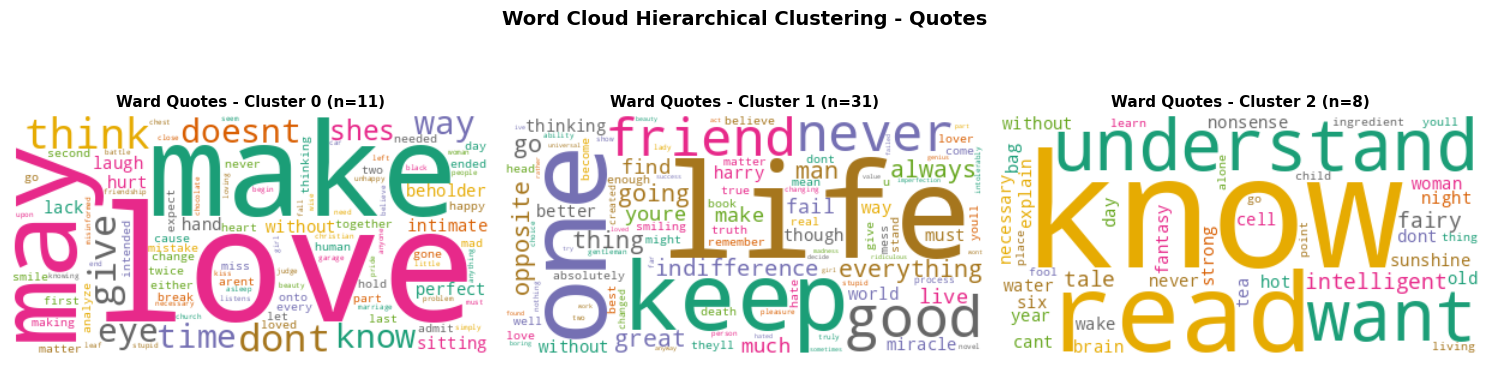

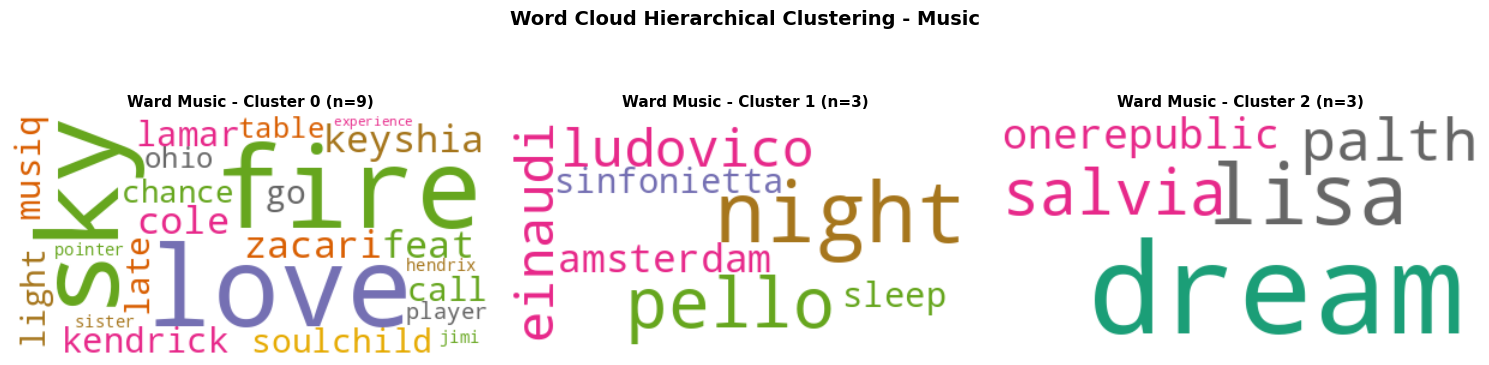

In [11]:
for name, df in datasets.items():
    k = n_clusters_dict[name]
    fig, axes = plt.subplots(1, k, figsize=(5 * k, 4))
    if k == 1:
        axes = [axes]

    for c in range(k):
        df_c = df[df['Ward_label'] == c]
        text_c = ' '.join(df_c['prepro'].values)
        if text_c.strip():
            wc = WordCloud(background_color='white', max_words=100, colormap='Dark2').generate(text_c)
            axes[c].imshow(wc, interpolation='bilinear')
        axes[c].set_title(f'Ward {name} - Cluster {c} (n={len(df_c)})', fontsize=11, fontweight='bold')
        axes[c].axis('off')

    plt.suptitle(f'Word Cloud Hierarchical Clustering - {name}', fontsize=14, fontweight='bold', y=1.02)
    plt.tight_layout()
    plt.show()

## **6. Analisis Perbandingan KMeans vs Hierarchical**

In [12]:
results = []
for name, df in datasets.items():
    df_fe = features_tfidf[name]
    sil_km = metrics.silhouette_score(df_fe, df['Kmeans_label'], metric='euclidean')
    sil_ward = metrics.silhouette_score(df_fe, df['Ward_label'], metric='euclidean')
    ari = metrics.adjusted_rand_score(df['Kmeans_label'], df['Ward_label'])

    results.append({
        'Dataset': name,
        'n_clusters': n_clusters_dict[name],
        'Silhouette (KMeans)': round(sil_km, 4),
        'Silhouette (Hierarchical)': round(sil_ward, 4),
        'Adjusted Rand Index (ARI)': round(ari, 4)
    })

df_comparison = pd.DataFrame(results)
display(df_comparison)

,Dataset,n_clusters,Silhouette (KMeans),Silhouette (Hierarchical),Adjusted Rand Index (ARI)
0,Quotes,3,0.0062,0.0129,0.3861
1,Music,3,0.1009,0.1009,1.0000
